# La red como grafo: dónde se parte la red de carriles

**Avanzado · Jornada 3 · Bloque 3.3 · diapositivas red-grafo, articulacion, intermediacion, demo-obras, cortes, riesgos y ejercicio-tramos**

¿Qué cruces de la red de carriles bici son puntos únicos de fallo? Grafo con networkx, intermediación, puntos de articulación, la demo de los cortes y el ejercicio de los tres tramos nuevos.

**Cómo usarlo.** En Google Colab: menú *Entorno de ejecución → Ejecutar todo* (*Runtime → Run all*). La primera vez tarda un poco: descarga los datos del curso. En Jupyter: *Ejecutar → Ejecutar todo*.

El código está a la vista. **Si no programas**, lee los comentarios, cambia los valores marcados con `# ←` y vuelve a ejecutar. **Si programas**, completa los huecos marcados con `# COMPLETAD`.

In [1]:
# Preparación: busca los datos del curso, instala lo que falte en Colab y carga el estilo.
# No hace falta tocar nada.
import importlib.util
import subprocess
import sys
from pathlib import Path


def buscar_proyecto():
    """La carpeta que contiene datos/avanzado y scripts/estilo.py."""
    aqui = Path.cwd()
    for carpeta in (aqui, *aqui.parents):
        if (carpeta / "scripts" / "estilo.py").exists() and (carpeta / "datos" / "avanzado").exists():
            return carpeta
    if "google.colab" in sys.modules:  # en Colab: descarga una vez el material público del curso
        destino = Path("/content/curso-analitica-cuadernos")
        if not destino.exists():
            subprocess.run(["git", "clone", "--quiet", "--depth", "1",
                            "https://github.com/castrorbea/curso-analitica-cuadernos.git", str(destino)], check=True)
        return destino
    raise FileNotFoundError("No encuentro los datos del curso: abre este cuaderno desde cuadernos/avanzado/.")


PROYECTO = buscar_proyecto()
DATOS = PROYECTO / "datos" / "avanzado"
for ruta in (PROYECTO / "scripts", PROYECTO / "cuadernos" / "avanzado"):
    if str(ruta) not in sys.path:
        sys.path.insert(0, str(ruta))
if "google.colab" in sys.modules and importlib.util.find_spec("h3") is None:
    subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", "h3"], check=True)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import bici    # rutas, descarga de la telemetría completa y hora local
import estilo  # colores, letra y formato numérico español del curso

# estilo.py fija el modo sin pantalla de matplotlib (para guardar PNG); en el cuaderno, los gráficos se ven.
get_ipython().run_line_magic("matplotlib", "inline")
pd.set_option("display.max_columns", 30)
print("Listo. Datos en", DATOS)


Listo. Datos en /Users/acastro/dev/cursos-analitica-datos/datos/avanzado


## La pregunta

¿Qué parte de la red de carriles bici de BiciCiudad es más frágil? Si un cruce se cierra por obras,
¿cuántas estaciones se quedan aisladas? La teoría de grafos, que nació con Euler y los siete
puentes de Königsberg, responde con unas pocas líneas de código.

> **Mensaje clave del bloque:** la red no falla por su eslabón medio, sino por el que nadie había dibujado.

## 1. Cargar los datos y montar el grafo

Tres tablas muy sencillas:

- `nodos.csv`: los cruces, con su posición;
- `aristas.csv`: los tramos de carril entre dos cruces, con longitud, capacidad y tipo (`carril` o
  `puente`);
- `estaciones.csv`: de qué cruce cuelga cada una de las 40 estaciones.

`networkx` las convierte en un grafo con una línea.

In [2]:
%matplotlib inline
import networkx as nx

# Los gráficos, dentro del cuaderno; las tablas, con coma decimal.
pd.set_option("display.float_format", lambda x: estilo.num(x, 2))
CARPETA = DATOS / "red_carriles"
nodos = pd.read_csv(CARPETA / "nodos.csv")
aristas = pd.read_csv(CARPETA / "aristas.csv")
estaciones = pd.read_csv(CARPETA / "estaciones.csv")
rio = pd.read_csv(CARPETA / "rio.csv")

# La línea: cada fila de aristas es un tramo entre dos cruces, con sus atributos.
red = nx.from_pandas_edgelist(aristas, "nodo_a", "nodo_b",
                              edge_attr=["longitud_m", "capacidad_bicis_h", "tipo"])

print(f"{red.number_of_nodes()} cruces y {red.number_of_edges()} tramos, "
      f"{estilo.num(aristas['longitud_m'].sum() / 1000)} km de carril; {len(estaciones)} estaciones")
print("¿Está todo conectado?", nx.is_connected(red))
aristas.head()

180 cruces y 260 tramos, 235 km de carril; 40 estaciones
¿Está todo conectado? True


,tramo_id,nodo_a,nodo_b,longitud_m,capacidad_bicis_h,tipo
0,T001,N001,N003,810,1500,carril
1,T002,N001,N006,630,800,carril
2,T003,N002,N003,750,600,carril
3,T004,N002,N009,1130,800,carril
4,T005,N004,N005,580,800,carril


Para dibujarla: las coordenadas son inventadas (en pleno Atlántico), así que pintamos en km respecto
al centro de la ciudad, sin mapa de fondo. Esta celda solo prepara el dibujo.

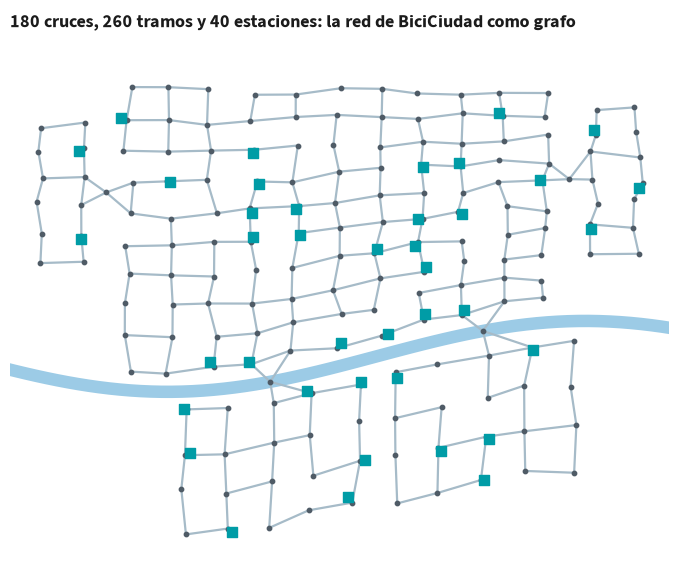

In [3]:
from matplotlib.collections import LineCollection

CENTRO_LAT, CENTRO_LON = 40.0, -12.5
KM_POR_GRADO_LAT = 110.574
KM_POR_GRADO_LON = 111.320 * np.cos(np.radians(CENTRO_LAT))


def a_km(tabla):
    """Añade x (km al este) e y (km al norte) del centro."""
    return tabla.assign(x=(tabla["lon"] - CENTRO_LON) * KM_POR_GRADO_LON,
                        y=(tabla["lat"] - CENTRO_LAT) * KM_POR_GRADO_LAT)


nodos, estaciones, rio = a_km(nodos), a_km(estaciones), a_km(rio)
xy = nodos.set_index("nodo_id")[["x", "y"]]


def dibujar_red(ax, grafo=red, resaltar=(), etiquetas=False, tramos_nuevos=()):
    """Río, tramos, cruces y estaciones. Resalta en naranja los cruces de `resaltar`."""
    ax.plot(rio["x"], rio["y"], color="#9CCBE6", lw=9, solid_capstyle="round", zorder=1)
    segmentos = [[xy.loc[a].to_numpy(), xy.loc[b].to_numpy()] for a, b in grafo.edges()]
    ax.add_collection(LineCollection(segmentos, colors=estilo.GRIS, linewidths=1.6, zorder=2))
    for a, b in tramos_nuevos:
        ax.plot(*zip(xy.loc[a], xy.loc[b]), color=estilo.AZUL, lw=4, zorder=3)
    ax.scatter(xy["x"], xy["y"], s=10, color=estilo.TEXTO_2, zorder=3)
    ax.scatter(estaciones["x"], estaciones["y"], marker="s", s=45, color=estilo.TURQUESA, zorder=4,
               label="estación")
    if len(resaltar):
        ax.scatter(xy.loc[list(resaltar), "x"], xy.loc[list(resaltar), "y"], s=260, color=estilo.NARANJA,
                   edgecolor="white", linewidth=2, zorder=5)
    if etiquetas:
        for nodo, (x, y) in xy.iterrows():
            ax.text(x, y + 0.12, nodo, fontsize=6.5, ha="center", va="bottom", color=estilo.TEXTO, zorder=6)
    ax.set_xlim(xy["x"].min() - 0.6, xy["x"].max() + 0.6)
    ax.set_ylim(xy["y"].min() - 0.6, xy["y"].max() + 0.6)
    ax.set_aspect("equal")
    ax.axis("off")


fig, ax = plt.subplots(figsize=(10, 6.5))
dibujar_red(ax)
ax.set_title("180 cruces, 260 tramos y 40 estaciones: la red de BiciCiudad como grafo")
plt.show()

## 2. El cruce más central: intermediación

La **centralidad de intermediación** de un cruce es la proporción de los caminos más cortos entre
todos los pares de cruces que pasan por él. Es el cruce por el que pasa todo el mundo: el que saldría
en rojo en cualquier mapa de tráfico.

intermediación de v = Σ (caminos más cortos de s a t que pasan por v ÷ caminos más cortos de s a t)
÷ número de pares, con número de pares = (n − 1) × (n − 2) ÷ 2 = 179 × 178 ÷ 2 = 15.931.

Sin más indicaciones, `networkx` mide «más corto» **contando tramos**, no metros.

In [4]:
intermediacion = pd.Series(nx.betweenness_centrality(red), name="intermediacion").sort_values(ascending=False)
intermediacion.head(5).to_frame()

,intermediacion
N067,"0,23"
N064,"0,20"
N134,"0,20"
N124,"0,19"
N052,"0,17"


In [5]:
# La misma cuenta sin dividir: cuántos pares (s, t) pasan por cada cruce. Si hay dos caminos
# igual de cortos, cada uno cuenta la mitad.
pares = (red.number_of_nodes() - 1) * (red.number_of_nodes() - 2) // 2
pares_por_cruce = pd.Series(nx.betweenness_centrality(red, normalized=False))
print(f"Pares de cruces (sin contar v): {estilo.num(pares)}")
print(f"N067: {estilo.num(pares_por_cruce['N067'])} pares → {estilo.num(pares_por_cruce['N067'] / pares, 2)}")

# Trampa: ¿«más corto» en qué? Con los metros como distancia, el más central es otro cruce.
por_metros = pd.Series(nx.betweenness_centrality(red, weight="longitud_m")).sort_values(ascending=False)
print(f"Contando metros, el más central es {por_metros.index[0]} ({estilo.num(por_metros.iloc[0], 2)})")

Pares de cruces (sin contar v): 15.931
N067: 3.622 pares → 0,23
Contando metros, el más central es N109 (0,24)


## 3. Los cruces críticos: puntos de articulación y puentes

- Un **punto de articulación** es un cruce que, si desaparece, parte la red en trozos.
- Un **puente**, en sentido de grafos, es un tramo que, si desaparece, también la parte. Ojo: aquí
  «puente» es un término técnico, no un puente sobre el río.

`networkx` los encuentra en una línea cada uno.

In [6]:
articulaciones = list(nx.articulation_points(red))
puentes = list(nx.bridges(red))
print(f"Puntos de articulación: {articulaciones}")
print(f"Tramos que son puente (en sentido de grafos): {len(puentes)}")
print(f"¿Es el cruce más central ({intermediacion.index[0]}) punto de articulación?",
      intermediacion.index[0] in articulaciones)

Puntos de articulación: ['N064', 'N134', 'N163', 'N013']
Tramos que son puente (en sentido de grafos): 0
¿Es el cruce más central (N067) punto de articulación? False


**Trampa: central no es crítico.** El cruce de mayor intermediación está en pleno centro y no es punto
de articulación: si cae, hay rodeos. Los cuatro puntos de articulación están lejos del centro; los dos
puentes son muy centrales (0,20), pero lo que los hace críticos es que no tienen rodeo.

¿Cuántas estaciones aísla cada uno? Contamos como aisladas las estaciones que quedan fuera del trozo
más grande de la red (incluidas las que cuelgan del propio cruce cortado).

In [7]:
estaciones_por_cruce = estaciones.groupby("nodo_id").size()


def estaciones_aisladas(grafo):
    """Estaciones que no están en el trozo más grande de la red."""
    if grafo.number_of_nodes() == 0:
        return len(estaciones)
    principal = max(nx.connected_components(grafo), key=len)
    return len(estaciones) - int(estaciones_por_cruce.reindex(list(principal)).fillna(0).sum())


# Los nombres con los que se conoce a estos cuatro cruces en la ciudad.
NOMBRES = {"N064": "Puente Nuevo", "N134": "Puente de Hierro", "N163": "Paso de la Ronda",
           "N013": "Pasarela de la Vía"}

filas = []
for cruce in articulaciones:
    sin_cruce = red.copy()
    sin_cruce.remove_node(cruce)
    filas.append({"cruce": cruce, "nombre": NOMBRES.get(cruce, ""),
                  "intermediacion": intermediacion[cruce],
                  "estaciones_aisladas": estaciones_aisladas(sin_cruce)})
tabla_articulacion = pd.DataFrame(filas).sort_values("estaciones_aisladas", ascending=False)
tabla_articulacion

,cruce,nombre,intermediacion,estaciones_aisladas
0,N064,Puente Nuevo,"0,20",7
1,N134,Puente de Hierro,"0,20",5
2,N163,Paso de la Ronda,"0,15",3
3,N013,Pasarela de la Vía,"0,13",2


## 4. Demo: cortamos cruces como si fueran obras

Antes de ejecutar nada: si fuerais un saboteador (o el ayuntamiento planificando obras), ¿qué cruce
cortaríais primero? ¿Cuántos cortes al azar harían falta para aislar a la mitad de las estaciones?
Apuntad la apuesta.

**Paso 1. Un corte al azar.** Ejecutad esta celda varias veces: cada vez corta un cruce distinto.

In [8]:
semilla = None  # ← sin semilla, cada ejecución corta un cruce distinto; con un número, siempre el mismo

azar = np.random.default_rng(semilla)
cruce = azar.choice(list(red.nodes()))
con_obras = red.copy()
con_obras.remove_node(cruce)
print(f"Cortado el cruce {cruce}. Estaciones aisladas: {estaciones_aisladas(con_obras)}")

Cortado el cruce N177. Estaciones aisladas: 0


**Paso 2. El cruce más central.** El de mayor intermediación, por el que pasa casi una cuarta parte de
los caminos más cortos.

In [9]:
con_obras = red.copy()
con_obras.remove_node(intermediacion.index[0])
print(f"Cortado {intermediacion.index[0]} (intermediación {estilo.num(intermediacion.iloc[0], 2)}): "
      f"estaciones aisladas: {estaciones_aisladas(con_obras)}")

Cortado N067 (intermediación 0,23): estaciones aisladas: 0


**Paso 3. Cortes con criterio.** Los cuatro puntos de articulación, uno tras otro, empezando por el que
más aísla.

In [10]:
con_obras = red.copy()
for cruce in tabla_articulacion["cruce"]:
    con_obras.remove_node(cruce)
    print(f"Cortado {cruce} ({NOMBRES[cruce]}): {estaciones_aisladas(con_obras)} estaciones aisladas en total")

Cortado N064 (Puente Nuevo): 7 estaciones aisladas en total
Cortado N134 (Puente de Hierro): 12 estaciones aisladas en total
Cortado N163 (Paso de la Ronda): 15 estaciones aisladas en total
Cortado N013 (Pasarela de la Vía): 17 estaciones aisladas en total


**Paso 4. La simulación completa.** Cien veces: cortar 40 cruces al azar, uno tras otro, y contar las
estaciones aisladas tras cada corte. La semilla es la del generador de los datos, para que salga lo
mismo que en la diapositiva.

In [11]:
N_SIMULACIONES = 100           # ← repeticiones de los cortes al azar
MAX_CORTES = 40                # ← cruces cortados en cada repetición
SEMILLA_CORTES = [2026, 8, 3]  # ← la misma que el generador de los datos

azar = np.random.default_rng(SEMILLA_CORTES)
lista_cruces = list(red.nodes())
aisladas_azar = np.zeros(MAX_CORTES + 1)
for _ in range(N_SIMULACIONES):
    orden = azar.permutation(len(lista_cruces))
    con_obras = red.copy()
    for k in range(1, MAX_CORTES + 1):
        con_obras.remove_node(lista_cruces[orden[k - 1]])
        aisladas_azar[k] += estaciones_aisladas(con_obras)
aisladas_azar /= N_SIMULACIONES

# Los cortes dirigidos: los cuatro puntos de articulación, en orden.
dirigidos = [0]
con_obras = red.copy()
for cruce in tabla_articulacion["cruce"]:
    con_obras.remove_node(cruce)
    dirigidos.append(estaciones_aisladas(con_obras))

print(f"4 cortes al azar: {estilo.num(aisladas_azar[4], 1)} estaciones aisladas de media")
print(f"4 cortes en los puntos de articulación: {dirigidos[4]}")
print(f"40 cortes al azar: {estilo.num(aisladas_azar[40])} de media")

4 cortes al azar: 1,2 estaciones aisladas de media
4 cortes en los puntos de articulación: 17
40 cortes al azar: 19 de media


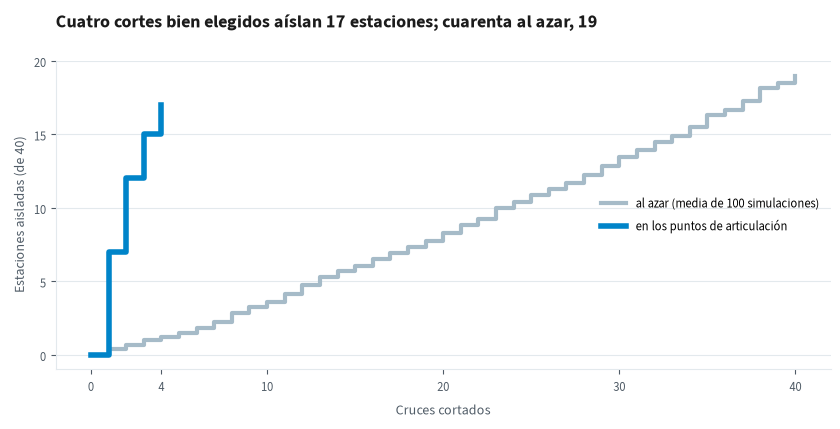

In [12]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.step(range(MAX_CORTES + 1), aisladas_azar, where="post", color=estilo.GRIS, lw=3,
        label=f"al azar (media de {N_SIMULACIONES} simulaciones)")
ax.step(range(len(dirigidos)), dirigidos, where="post", color=estilo.AZUL, lw=4,
        label="en los puntos de articulación")
ax.set_xlabel("Cruces cortados")
ax.set_ylabel("Estaciones aisladas (de 40)")
ax.set_yticks([0, 5, 10, 15, 20])
ax.set_xticks([0, 4, 10, 20, 30, 40])
ax.legend(loc="center right")
ax.set_title(f"Cuatro cortes bien elegidos aíslan {dirigidos[4]} estaciones; "
             f"cuarenta al azar, {estilo.num(aisladas_azar[40])}")
plt.show()

Las redes aguantan bien los fallos al azar, que son la mayoría, y son muy frágiles frente a unos pocos
fallos concretos. Esos fallos no se encuentran mirando dónde está el tráfico, sino buscando **dónde no hay
alternativa**: dos puentes sobre el río, un paso sobre la ronda y una pasarela sobre la vía del tren.
Los dos puentes también son muy centrales (0,20, casi como N067), porque todo lo que cruza el río pasa
por ellos; la diferencia es que N067 tiene rodeo y ellos no. La pregunta no es cuánto se usa un cruce,
sino si tiene alternativa.

## 5. Ejercicio (en equipos, 25 min): tres tramos nuevos

Las reglas:

1. Podéis añadir **tres tramos** entre cruces que ya existen.
2. Cada tramo, de **1.200 m como máximo**. La longitud de un tramo nuevo es la distancia en línea recta
   por 1,1, como la de los tramos que ya hay (las calles no van en línea recta).
3. Gana el equipo que deje **menos puntos de articulación**; si empatan, el que use menos metros.

El mapa tiene el identificador de cada cruce y los cuatro puntos de articulación en naranja. Pensad
antes de probar a ciegas: ¿qué barrio cuelga de qué cruce?

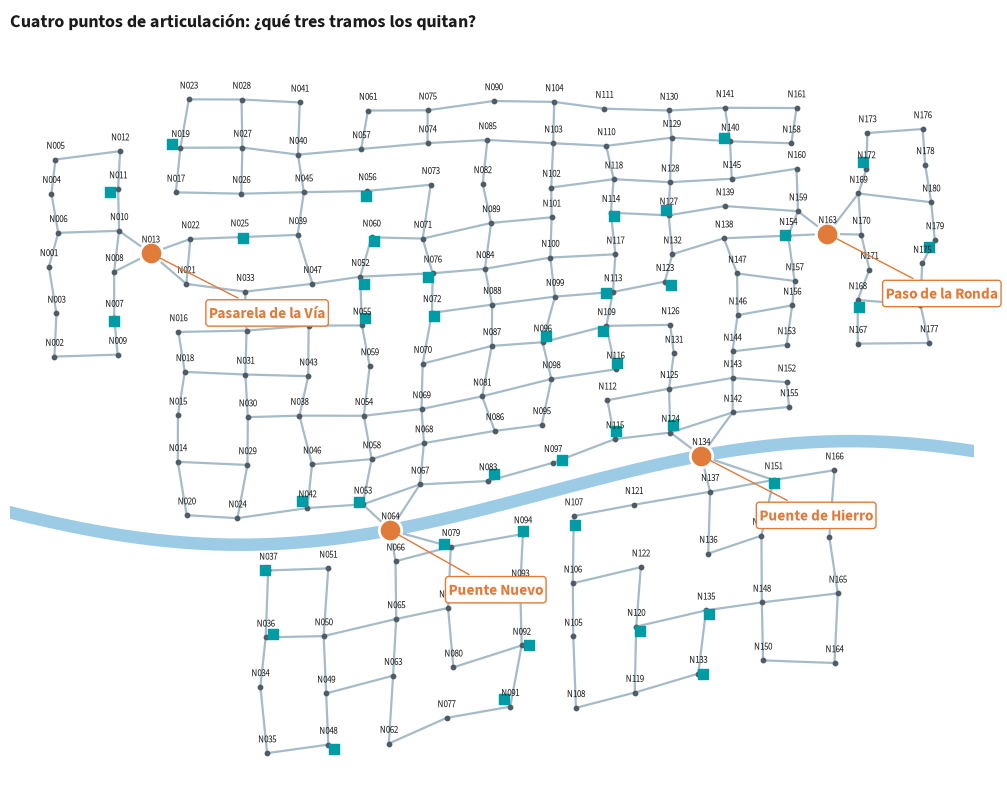

In [13]:
fig, ax = plt.subplots(figsize=(14, 9.5))
dibujar_red(ax, resaltar=articulaciones, etiquetas=True)
for cruce in articulaciones:
    ax.annotate(NOMBRES[cruce], xy=tuple(xy.loc[cruce]), xytext=(xy.loc[cruce, "x"] + 0.9, xy.loc[cruce, "y"] - 1.0),
                fontsize=11, weight="bold", color=estilo.NARANJA, zorder=7,
                bbox={"boxstyle": "round,pad=0.2", "fc": "white", "ec": estilo.NARANJA},
                arrowprops={"arrowstyle": "-", "color": estilo.NARANJA})
ax.set_title("Cuatro puntos de articulación: ¿qué tres tramos los quitan?")
plt.show()

Dos herramientas: `cruces_cerca` lista los cruces a los que se puede llegar desde uno con un tramo
nuevo, y `probar_tramos` comprueba vuestra propuesta y dice cuántos puntos de articulación quedan.

In [14]:
LONGITUD_MAXIMA_M = 1200  # ← regla del ejercicio


def longitud_m(a, b):
    """Longitud de un tramo nuevo: línea recta por 1,1, redondeada a 10 m."""
    return int(round(float(np.hypot(*(xy.loc[a] - xy.loc[b]))) * 1000 * 1.1, -1))


def cruces_cerca(cruce, maximo_m=LONGITUD_MAXIMA_M):
    """Cruces sin tramo directo con `cruce` a los que se llega con un tramo nuevo permitido."""
    filas = [{"hasta": otro, "longitud_m": longitud_m(cruce, otro)}
             for otro in xy.index if otro != cruce and not red.has_edge(cruce, otro)]
    tabla = pd.DataFrame(filas)
    return tabla[tabla["longitud_m"] <= maximo_m].sort_values("longitud_m")


def probar_tramos(tramos):
    """Añade los tramos nuevos a una copia de la red y cuenta los puntos de articulación."""
    nueva = red.copy()
    total_m = 0
    for a, b in tramos:
        if a not in xy.index or b not in xy.index:
            print(f"  {a}–{b}: no existe alguno de los dos cruces")
            continue
        largo = longitud_m(a, b)
        if largo > LONGITUD_MAXIMA_M:
            print(f"  {a}–{b}: {estilo.num(largo)} m, más de {estilo.num(LONGITUD_MAXIMA_M)} m; no vale")
            continue
        nueva.add_edge(a, b)
        total_m += largo
        print(f"  {a}–{b}: {estilo.num(largo)} m")
    quedan = sorted(nx.articulation_points(nueva))
    print(f"Tramos válidos: {estilo.num(total_m)} m en total. Puntos de articulación que quedan: "
          f"{len(quedan)} {quedan}")
    return nueva, quedan


cruces_cerca("N100")  # ← probad con otros cruces (si sale vacío, sus vecinos cercanos ya están unidos)

,hasta,longitud_m
87,N089,1160
97,N102,1190


In [15]:
# Vuestra propuesta: hasta tres pares de cruces ("N…", "N…").
tramos_nuevos = []  # ← COMPLETAD, por ejemplo [("N001", "N002"), ...]

red_nueva, quedan = probar_tramos(tramos_nuevos[:3])

Tramos válidos: 0 m en total. Puntos de articulación que quedan: 4 ['N013', 'N064', 'N134', 'N163']


## Qué os lleváis

- **Tres tablas bastan** (cruces, tramos y de qué cruce cuelga cada activo) para tener la red como grafo.
- **Central no es crítico.** El cruce más usado tiene rodeos; el crítico es el que no tiene alternativa.
- **Las redes aguantan el azar y caen por unos pocos puntos concretos.** Cuatro cortes bien elegidos
  aíslan casi tanto como cuarenta al azar.
- **El grafo da la dependencia entre activos** que pide cualquier análisis de riesgos.
- **Arreglar la estructura, no los síntomas:** un tramo bien puesto quita dos puntos de articulación.

> La red no falla por su eslabón medio, sino por el que nadie había dibujado.